# 11. Arquitectura del modelo 1D-CNN propuesto

**Objetivo:** documentar y representar la arquitectura utilizada en el experimento, mostrando sus capas, dimensiones, parámetros y flujo de procesamiento.

La arquitectura se analiza a partir del modelo entrenado previamente en el Notebook 09. No se realiza un nuevo entrenamiento.

In [1]:
import tensorflow as tf
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

MODEL_PATH = Path("../../resultados/nuevo_experimento/modelo_nueva_cnn.keras")
OUT_DIR = Path("../../resultados/nuevo_experimento")
FIG_DIR = OUT_DIR / "figuras"
TAB_DIR = OUT_DIR / "tablas"

FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

model = tf.keras.models.load_model(MODEL_PATH)

print("Modelo cargado correctamente.")
print("Número de capas:", len(model.layers))
print("Parámetros totales:", model.count_params())

Modelo cargado correctamente.
Número de capas: 6
Parámetros totales: 34529


## 1. Resumen de la arquitectura

La siguiente información se obtiene directamente del modelo entrenado. De esta manera, la descripción de la arquitectura coincide con la implementación ejecutada.

In [2]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape            ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 11, 32)          │           128 │
├─────────────────────────────────┼─────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 11, 96)          │         9,312 │
├─────────────────────────────────┼─────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 96)              │             0 │
│ (GlobalAveragePooling1D)        │                         │               │
├─────────────────────────────────┼─────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)             │        24,832 │
├─────────────────────────────────┼─────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)             │             0 │
├─────────────────────────────────┼─────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)               │           257 │
└─────────────────────────────────┴─────────────────────────┴───────────────┘

 Total params: 103,589 (404.65 KB)

 Trainable params: 34,529 (134.88 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 69,060 (269.77 KB)

## 2. Parámetros por capa

Se extrae automáticamente el número de parámetros entrenables y no entrenables de cada capa.

In [3]:
rows = []

for layer in model.layers:
    rows.append({
        "capa": layer.name,
        "tipo": layer.__class__.__name__,
        "forma_salida": str(layer.output.shape),
        "parametros": layer.count_params(),
        "entrenables": sum(
            int(tf.size(w).numpy()) for w in layer.trainable_weights
        ),
        "no_entrenables": sum(
            int(tf.size(w).numpy()) for w in layer.non_trainable_weights
        )
    })

arquitectura = pd.DataFrame(rows)

print(arquitectura.to_string(index=False))

arquitectura.to_csv(
    TAB_DIR / "arquitectura_capas.csv",
    index=False
)

                    capa                   tipo   forma_salida  parametros  entrenables  no_entrenables
                  conv1d                 Conv1D (None, 11, 32)         128          128               0
                conv1d_1                 Conv1D (None, 11, 96)        9312         9312               0
global_average_pooling1d GlobalAveragePooling1D     (None, 96)           0            0               0
                   dense                  Dense    (None, 256)       24832        24832               0
                 dropout                Dropout    (None, 256)           0            0               0
                 dense_1                  Dense      (None, 1)         257          257               0


## 3. Verificación del número de parámetros

El número total de parámetros debe coincidir con el valor obtenido durante el entrenamiento del Notebook 09.

In [4]:
TOTAL_ESPERADO = 34529
TOTAL_OBTENIDO = model.count_params()

print("Parámetros esperados:", TOTAL_ESPERADO)
print("Parámetros obtenidos:", TOTAL_OBTENIDO)

assert TOTAL_OBTENIDO == TOTAL_ESPERADO

print("Verificación satisfactoria: la arquitectura contiene 34,529 parámetros.")

Parámetros esperados: 34529
Parámetros obtenidos: 34529
Verificación satisfactoria: la arquitectura contiene 34,529 parámetros.


## 4. Flujo de procesamiento

El modelo recibe las variables clínicas como una secuencia de características y las procesa mediante las capas convolucionales antes de realizar la clasificación final.

El flujo general es:

**Variables clínicas → capas convolucionales → reducción de características → capa densa → salida Sigmoid → clasificación cardiovascular.**

In [5]:
print("FLUJO DEL MODELO")
print("=" * 60)

for i, layer in enumerate(model.layers, start=1):
    print(
        f"{i}. {layer.name} | "
        f"{layer.__class__.__name__} | "
        f"salida={layer.output.shape} | "
        f"parámetros={layer.count_params()}"
    )

FLUJO DEL MODELO
1. conv1d | Conv1D | salida=(None, 11, 32) | parámetros=128
2. conv1d_1 | Conv1D | salida=(None, 11, 96) | parámetros=9312
3. global_average_pooling1d | GlobalAveragePooling1D | salida=(None, 96) | parámetros=0
4. dense | Dense | salida=(None, 256) | parámetros=24832
5. dropout | Dropout | salida=(None, 256) | parámetros=0
6. dense_1 | Dense | salida=(None, 1) | parámetros=257


## 5. Representación visual de la arquitectura

La siguiente figura resume visualmente el flujo del modelo. Los valores de parámetros se obtienen directamente de la arquitectura cargada.

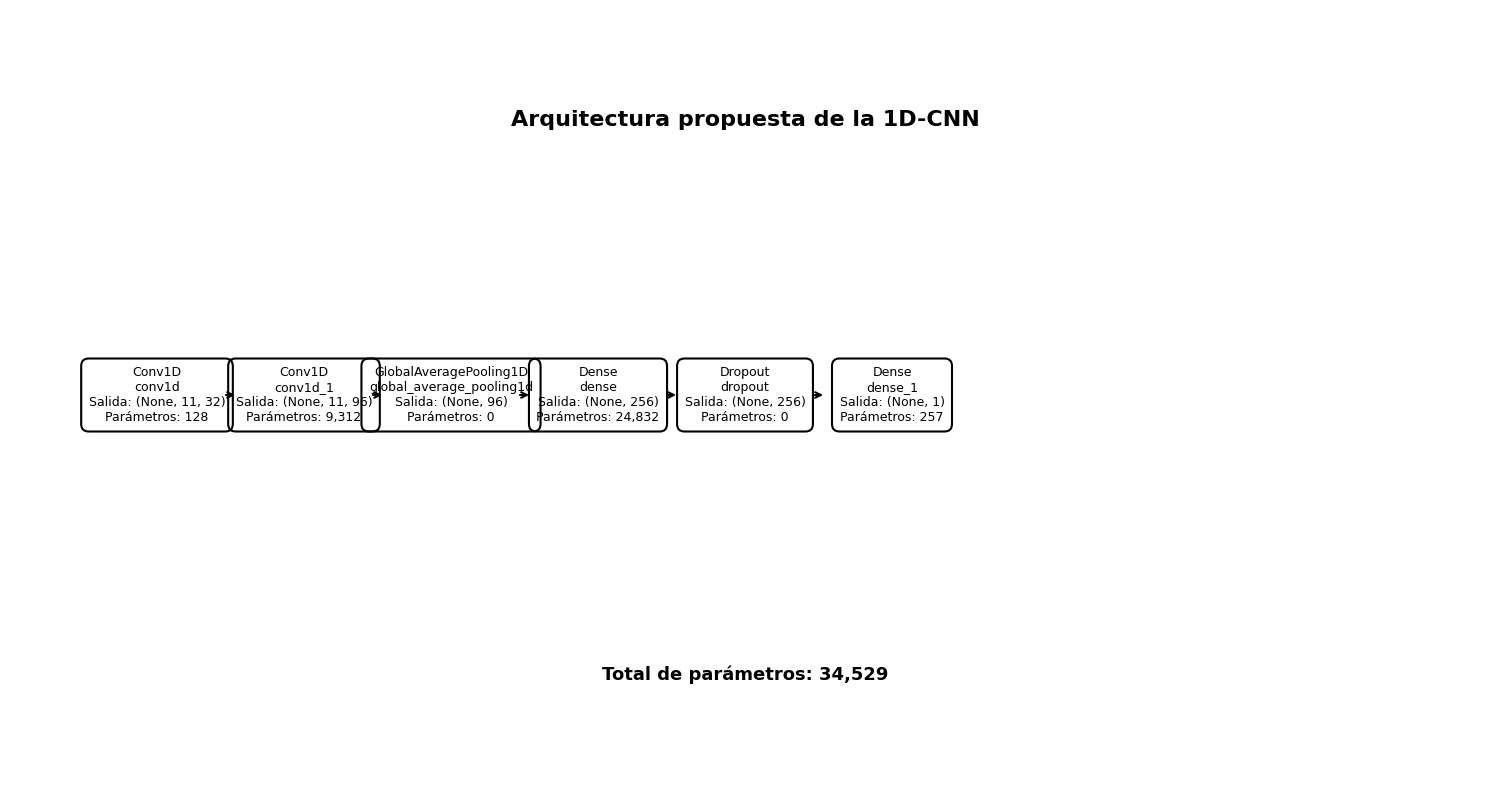

In [6]:
fig, ax = plt.subplots(figsize=(15, 8))

ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.axis("off")

layers = []

for layer in model.layers:
    layers.append({
        "nombre": layer.name,
        "tipo": layer.__class__.__name__,
        "params": layer.count_params(),
        "salida": str(layer.output.shape)
    })

x_positions = list(range(1, len(layers) + 1))

if len(x_positions) > 8:
    step = 8 / (len(x_positions) - 1)
    x_positions = [1 + i * step for i in range(len(layers))]

for i, (x, info) in enumerate(zip(x_positions, layers)):

    text = (
        f"{info['tipo']}\n"
        f"{info['nombre']}\n"
        f"Salida: {info['salida']}\n"
        f"Parámetros: {info['params']:,}"
    )

    ax.text(
        x,
        5,
        text,
        ha="center",
        va="center",
        fontsize=9,
        bbox=dict(
            boxstyle="round,pad=0.6",
            fill=False,
            linewidth=1.5
        )
    )

    if i < len(layers) - 1:
        ax.annotate(
            "",
            xy=(x_positions[i+1] - 0.45, 5),
            xytext=(x + 0.45, 5),
            arrowprops=dict(arrowstyle="->", linewidth=1.5)
        )

ax.text(
    5,
    8.5,
    "Arquitectura propuesta de la 1D-CNN",
    ha="center",
    fontsize=16,
    fontweight="bold"
)

ax.text(
    5,
    1.3,
    f"Total de parámetros: {model.count_params():,}",
    ha="center",
    fontsize=13,
    fontweight="bold"
)

fig.tight_layout()

fig.savefig(
    FIG_DIR / "arquitectura_nueva_cnn.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 6. Verificaciones finales

Se comprueba que el modelo pueda cargarse correctamente, que el número de parámetros coincida con el entrenamiento y que la tabla de arquitectura contenga todas las capas.

In [7]:
print("Número de capas:", len(model.layers))
print("Parámetros totales:", model.count_params())
print("Filas de la tabla de arquitectura:", len(arquitectura))

assert model.count_params() == 34529
assert len(arquitectura) == len(model.layers)
assert arquitectura["parametros"].sum() == 34529

print()
print("Todas las verificaciones fueron satisfactorias.")

Número de capas: 6
Parámetros totales: 34529
Filas de la tabla de arquitectura: 6

Todas las verificaciones fueron satisfactorias.


## 7. Conclusión

La arquitectura analizada corresponde exactamente al modelo utilizado en el experimento. La extracción automática permite documentar las capas, dimensiones y parámetros sin introducir modificaciones respecto al modelo entrenado.

El modelo contiene **34,529 parámetros**, valor que se encuentra dentro del rango de 30,000 a 50,000 parámetros establecido para el experimento.

Esta arquitectura constituye la implementación modificada respecto al modelo de referencia y será utilizada para el análisis final de desempeño.